# Beam splitter com dissipação

Simulação da evolução de dois modos acoplados por uma Hamiltoniana do tipo beam splitter, com operadores de colapso definidos para representar dissipação. Requer QuTiP, NumPy e Matplotlib. Execute em ambiente compatível com QuTiP 5.

Quantum object: dims=[[20, 20], [20, 20]], shape=(400, 400), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0.96980262+0.j 0.        +0.j 0.        +0.j ... 0.        +0.j
  0.        +0.j 0.        +0.j]
 [0.        +0.j 0.03015202+0.j 0.        +0.j ... 0.        +0.j
  0.        +0.j 0.        +0.j]
 [0.        +0.j 0.        +0.j 0.        +0.j ... 0.        +0.j
  0.        +0.j 0.        +0.j]
 ...
 [0.        +0.j 0.        +0.j 0.        +0.j ... 0.        +0.j
  0.        +0.j 0.        +0.j]
 [0.        +0.j 0.        +0.j 0.        +0.j ... 0.        +0.j
  0.        +0.j 0.        +0.j]
 [0.        +0.j 0.        +0.j 0.        +0.j ... 0.        +0.j
  0.        +0.j 0.        +0.j]]
Dimensões: [[20, 20], [20, 20]]


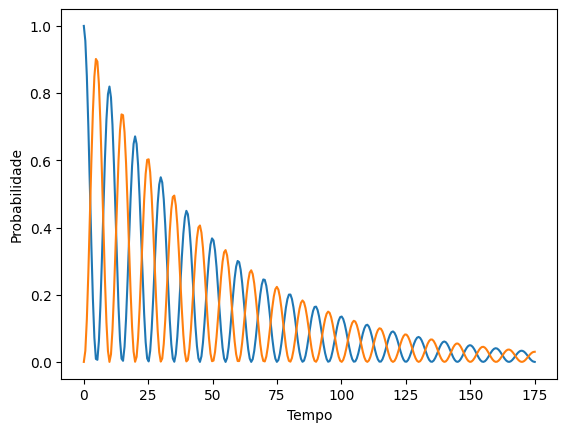

In [8]:
!pip install qutip
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image
from qutip import (about, destroy, hinton, ptrace, qdiags, qeye, steadystate,
                   tensor, wigner, wigner_cmap, basis, fidelity, mesolve,expect)

%matplotlib inline

#Tentar usar a Hamiltoniana de beamsplitter (troca), com um quantum de excitação em um dos sistemas e entender o que acontece com as oscilações Rabi

#Parâmetros

wo = 1.0 * 2 * np.pi #frequência da cavidade óptica
wm = 1.0 * 2 * np.pi # frequência da cavidade mecânica
g = 0.05 * 2 * np.pi #constante de acoplamento entre cavidades
No = 20 # número de cavidades ópticas no estado de fock
Nm = 20 # número de cavidades mecânicas no estado de fock
kappa = 0.02 #Taxa de dissipação na caviedade
gamma = 0.02 #Taxa de dissipação na cavidade
n_th= 0.0 # Taxa de temperatura

#Definir Operadores para a Hamiltoniana

a = tensor(destroy(No), qeye(Nm))
b = tensor(qeye(No), destroy(Nm))
num_b = b.dag() * b
num_a = a.dag() * a

#HAMILTONIANA

H = g * (a * b.dag() + a.dag() * b)

# Criar um quantoum de excitação

psi = tensor(basis(No,1),basis(Nm,0))

#Dissipação

c_ops = []

c_ops.append(np.sqrt(kappa) * a)
c_ops.append(np.sqrt(gamma * (n_th + 1)) * b)

if n_th > 0:
    c_ops.append(np.sqrt(gamma * n_th) * b.dag())



# Evolução Temporal

tlist = np.linspace(0,175,300)

output = mesolve(H,psi, tlist,c_ops,[])

# Escrever o Estado evouído
print(output.states[-1])
print(f"Dimensões: {output.states[-1].dims}")

#Probabilidade
proj_foton = psi * psi.dag()
proj_fonon = tensor(basis(No,0), basis(Nm,1))
proj_fonon = proj_fonon * proj_fonon.dag()

P = expect(proj_foton,output.states)
P_2 = expect(proj_fonon, output.states)

P, P_2

#Plotar gráfico de probabilidade x tempo, isso vai mostrar graficamente o que são as oscilações de Rabi (vão ser funções de seno e cosseno)

plt.plot(tlist,P)
plt.plot(tlist,P_2)
plt.xlabel("Tempo")
plt.ylabel("Probabilidade")
plt.show()
